Balanced counts  : [338 331 331]
Imbalanced counts: [797 151  52]


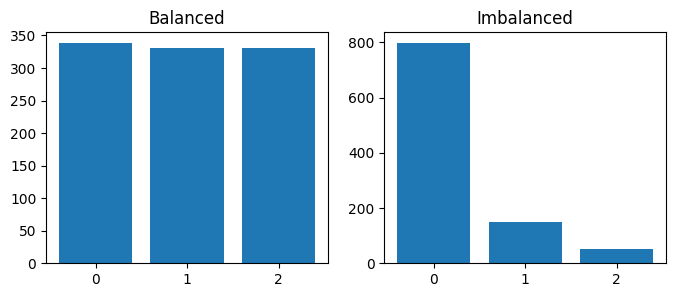

In [1]:
# Assignment 9    Implement Balanced and Imbalanced Multiclass Classification

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Balanced: roughly equal classes
Xb, yb = make_classification(n_samples=1000, n_features=6, n_informative=4, n_redundant=0,
                             n_classes=3, weights=[0.34, 0.33, 0.33], random_state=1)

# Imbalanced: class 0 is 80%, class 1 is 15%, class 2 is only 5%
Xi, yi = make_classification(n_samples=1000, n_features=6, n_informative=4, n_redundant=0,
                             n_classes=3, weights=[0.80, 0.15, 0.05], random_state=1)

print("Balanced counts  :", np.bincount(yb))
print("Imbalanced counts:", np.bincount(yi))

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1); plt.bar([0, 1, 2], np.bincount(yb)); plt.title("Balanced")
plt.subplot(1, 2, 2); plt.bar([0, 1, 2], np.bincount(yi)); plt.title("Imbalanced")
plt.show()

===== Balanced data =====
Accuracy: 0.573
              precision    recall  f1-score   support

           0       0.65      0.72      0.68       102
           1       0.57      0.64      0.60        99
           2       0.46      0.36      0.41        99

    accuracy                           0.57       300
   macro avg       0.56      0.57      0.56       300
weighted avg       0.56      0.57      0.57       300



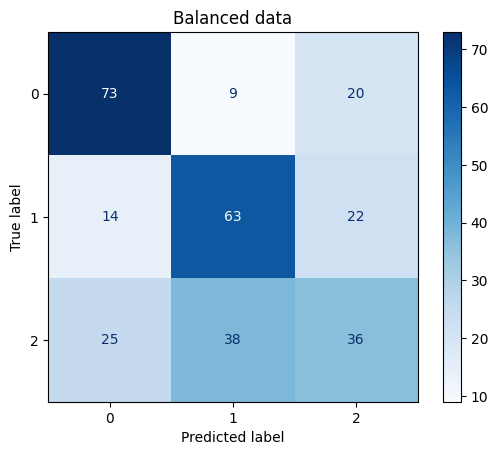

===== Imbalanced data =====
Accuracy: 0.883
              precision    recall  f1-score   support

           0       0.92      0.97      0.95       239
           1       0.68      0.71      0.70        45
           2       0.00      0.00      0.00        16

    accuracy                           0.88       300
   macro avg       0.53      0.56      0.55       300
weighted avg       0.84      0.88      0.86       300



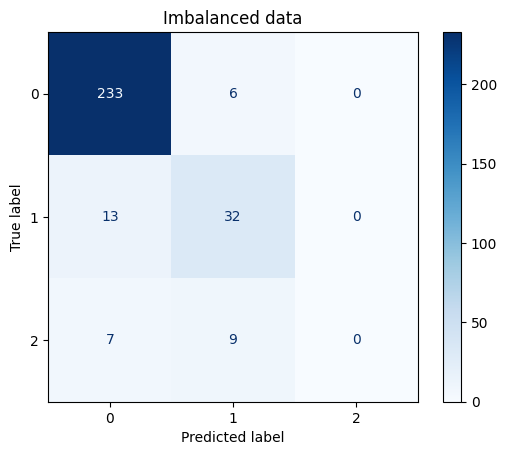

In [3]:
def run(X, y, title, class_weight=None):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    model = LogisticRegression(max_iter=1000, class_weight=class_weight).fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print("=====", title, "=====")
    print("Accuracy:", round(accuracy_score(y_te, pred), 3))
    print(classification_report(y_te, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_te, pred, cmap='Blues')
    plt.title(title)
    plt.show()

run(Xb, yb, "Balanced data")
run(Xi, yi, "Imbalanced data")

===== Imbalanced data + class_weight='balanced' =====
Accuracy: 0.71
              precision    recall  f1-score   support

           0       0.95      0.73      0.83       239
           1       0.55      0.73      0.63        45
           2       0.09      0.31      0.14        16

    accuracy                           0.71       300
   macro avg       0.53      0.59      0.53       300
weighted avg       0.84      0.71      0.76       300



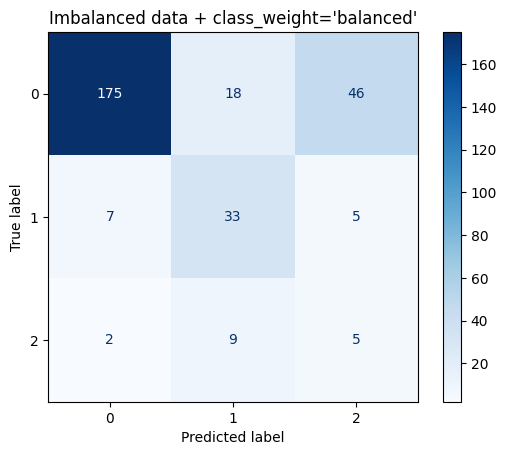

In [4]:
run(Xi, yi, "Imbalanced data + class_weight='balanced'", class_weight='balanced')